Predicting Stock Market Prices	Design and render comprehensive line visualizations that track and highlight the temporal evolution of TSLA closing prices, enabling trend discovery over varying time horizons.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv(
    "TSLA_cleaned_data.csv",
    parse_dates=["Date"]
)

data = data.sort_values("Date")

print("Dataset Shape:", data.shape)
display(data.head())

Dataset Shape: (100, 6)


,Date,Open,High,Low,Close,Volume
9,2025-01-02,377.53,386.12,374.68,381.88,97077442
84,2025-01-03,372.39,377.55,371.43,376.36,85746412
87,2025-01-06,377.69,381.99,373.44,380.68,56893889
51,2025-01-07,387.26,390.45,385.32,386.06,76990555
15,2025-01-08,372.81,379.96,368.15,375.53,100413036


In [3]:
data["Close"] = pd.to_numeric(data["Close"], errors="coerce")

# Remove missing dates and closing prices
data = data.dropna(subset=["Date", "Close"])

# Resolve duplicate dates for visualization
data = data.drop_duplicates(subset=["Date"], keep="first")

data = data.set_index("Date").sort_index()

display(data[["Close"]].head())

,Close
Date,
2025-01-02,381.88
2025-01-03,376.36
2025-01-06,380.68
2025-01-07,386.06
2025-01-08,375.53


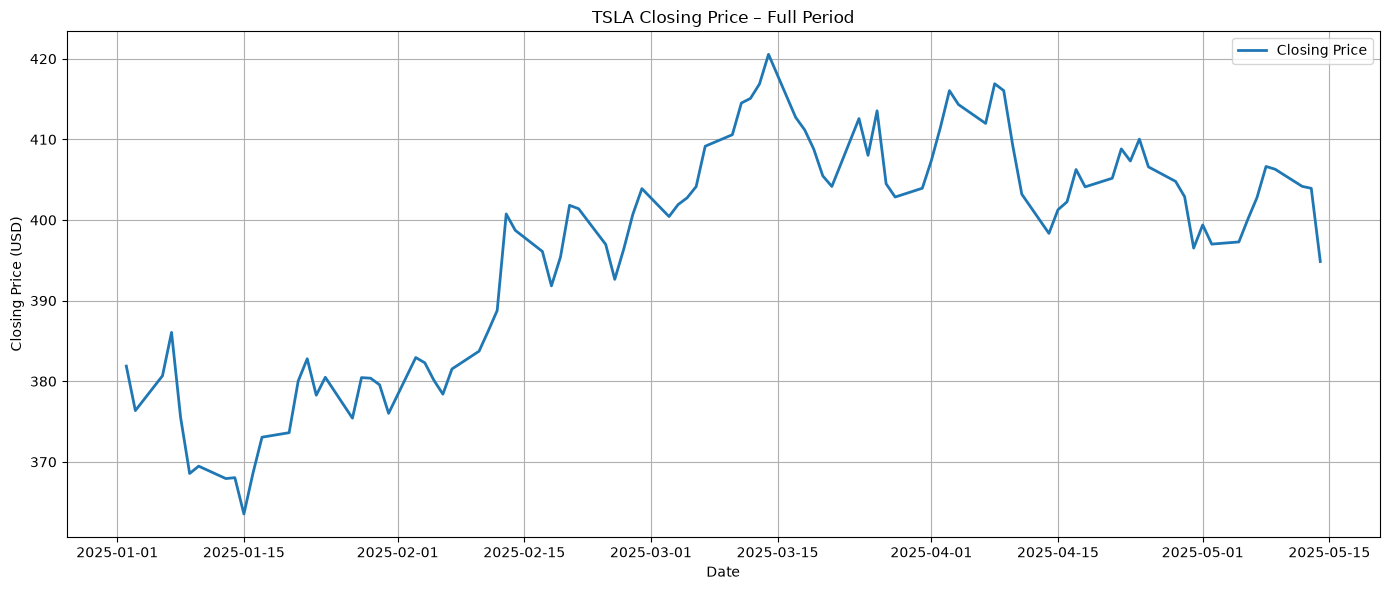

In [4]:
plt.figure(figsize=(14, 6))

plt.plot(
    data.index,
    data["Close"],
    label="Closing Price",
    linewidth=2
)

plt.title("TSLA Closing Price – Full Period")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

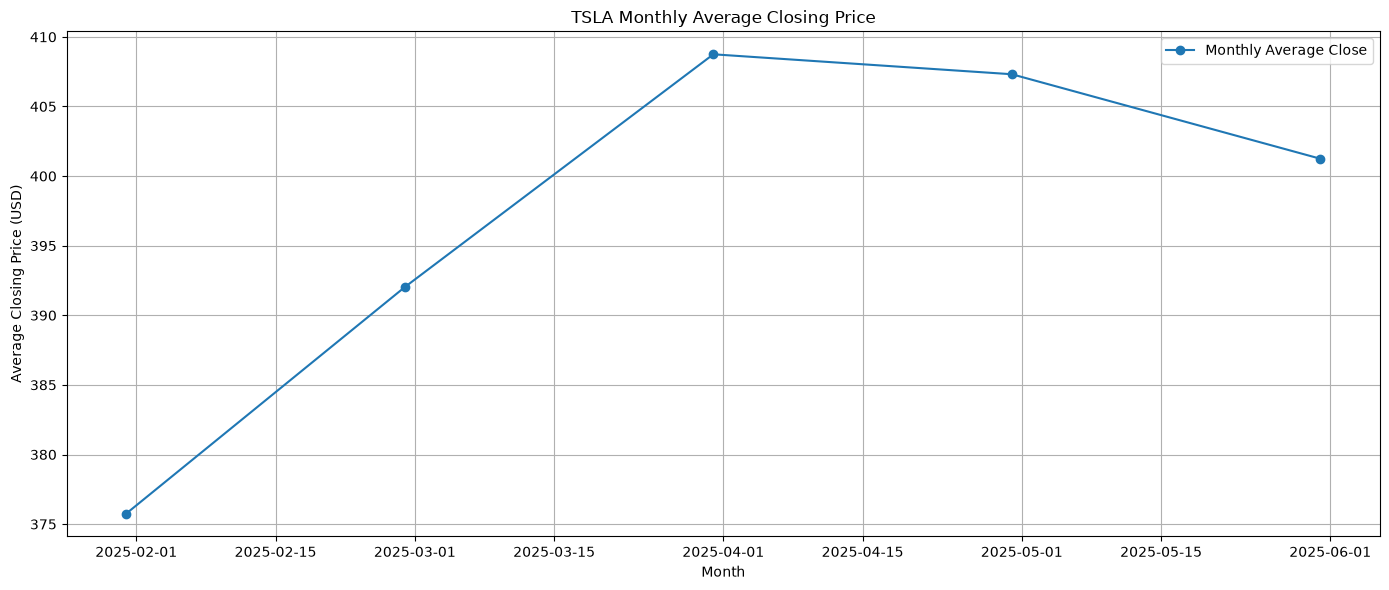

In [5]:
monthly_close = data["Close"].resample("ME").mean()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_close.index,
    monthly_close.values,
    marker="o",
    label="Monthly Average Close"
)

plt.title("TSLA Monthly Average Closing Price")
plt.xlabel("Month")
plt.ylabel("Average Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

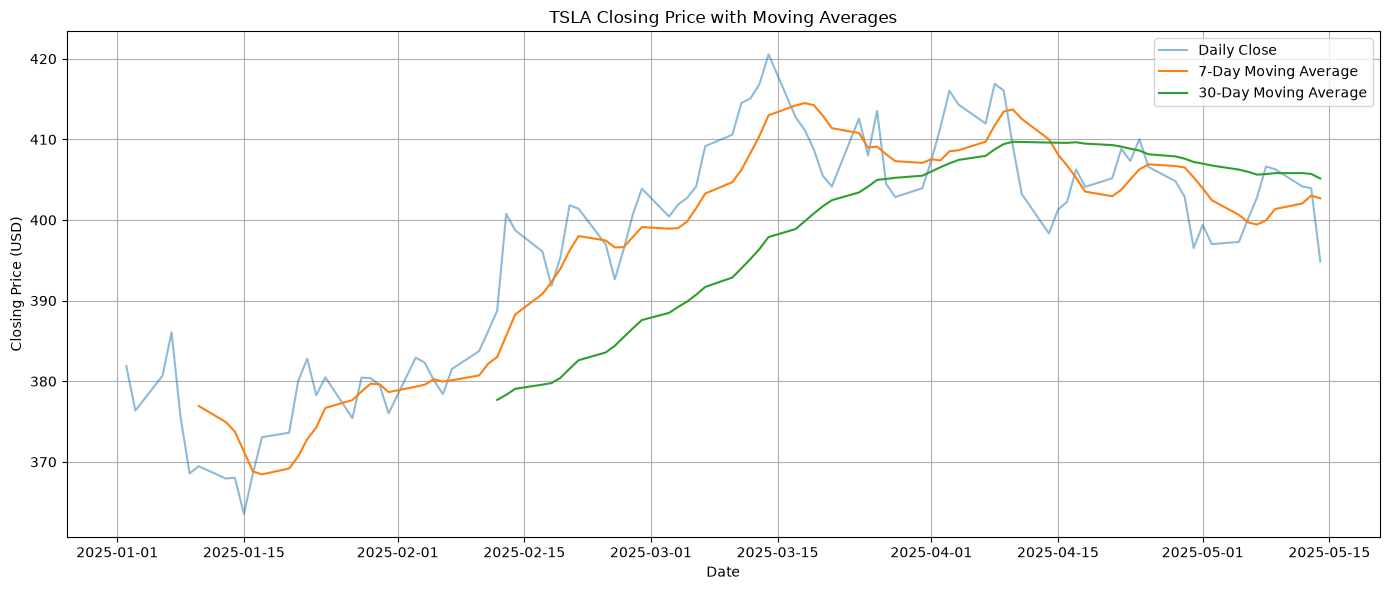

In [6]:
data["7_Day_MA"] = data["Close"].rolling(7).mean()
data["30_Day_MA"] = data["Close"].rolling(30).mean()

plt.figure(figsize=(14, 6))

plt.plot(data.index, data["Close"], label="Daily Close", alpha=0.5)
plt.plot(data.index, data["7_Day_MA"], label="7-Day Moving Average")
plt.plot(data.index, data["30_Day_MA"], label="30-Day Moving Average")

plt.title("TSLA Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

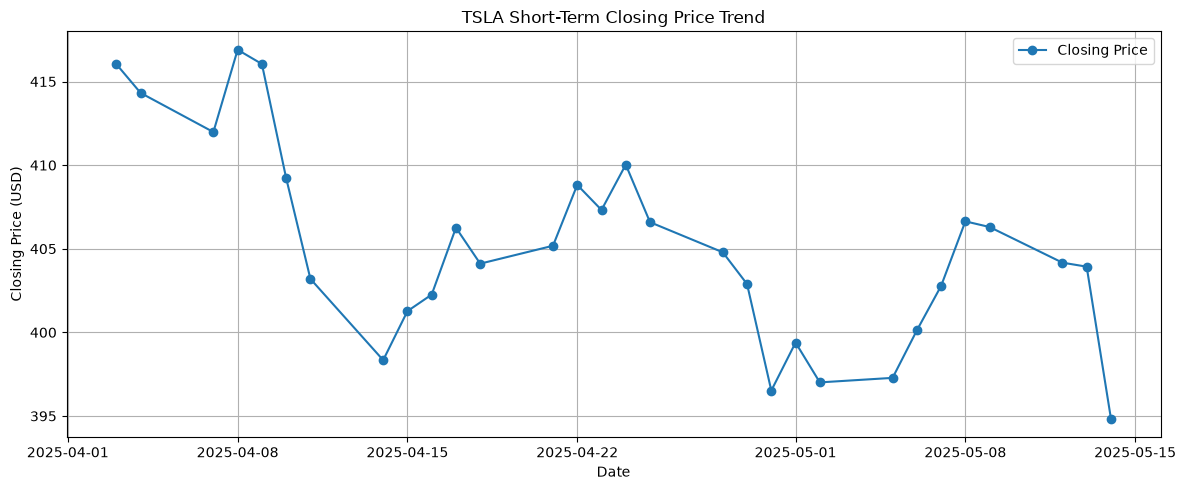

In [7]:
short_term = data.tail(30)

plt.figure(figsize=(12, 5))

plt.plot(
    short_term.index,
    short_term["Close"],
    marker="o",
    label="Closing Price"
)

plt.title("TSLA Short-Term Closing Price Trend")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

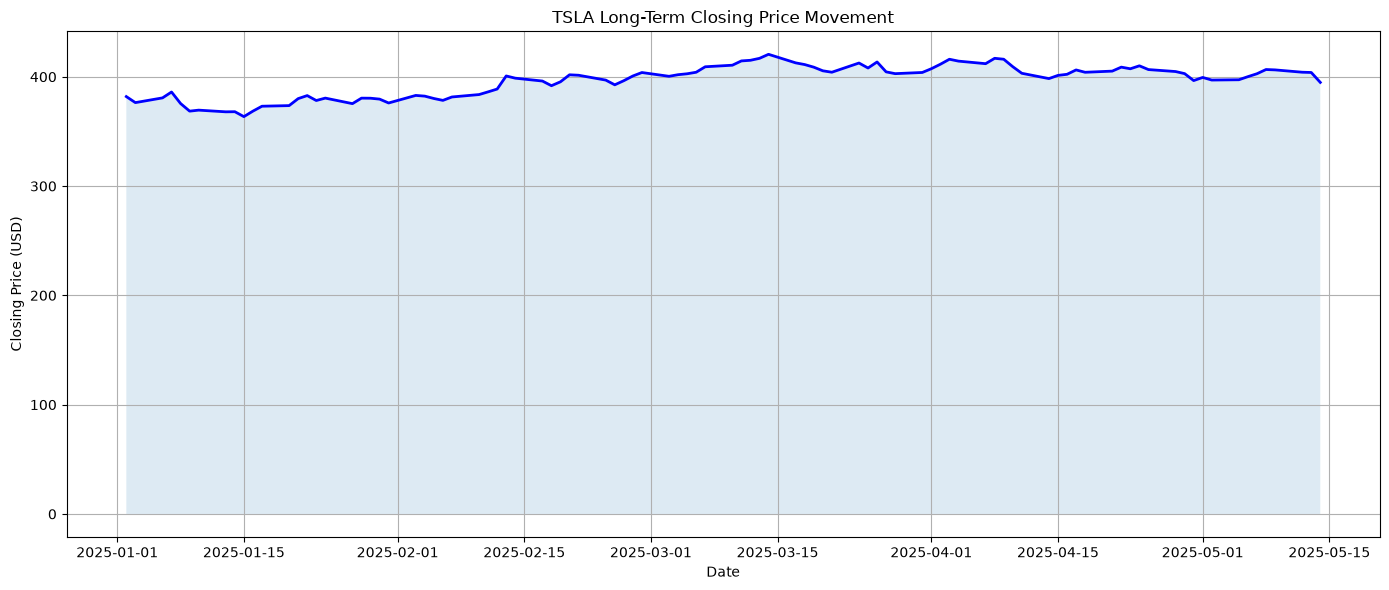

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(
    data.index,
    data["Close"],
    color="blue",
    linewidth=2
)

plt.fill_between(
    data.index,
    data["Close"],
    alpha=0.15
)

plt.title("TSLA Long-Term Closing Price Movement")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)
plt.tight_layout()
plt.show()

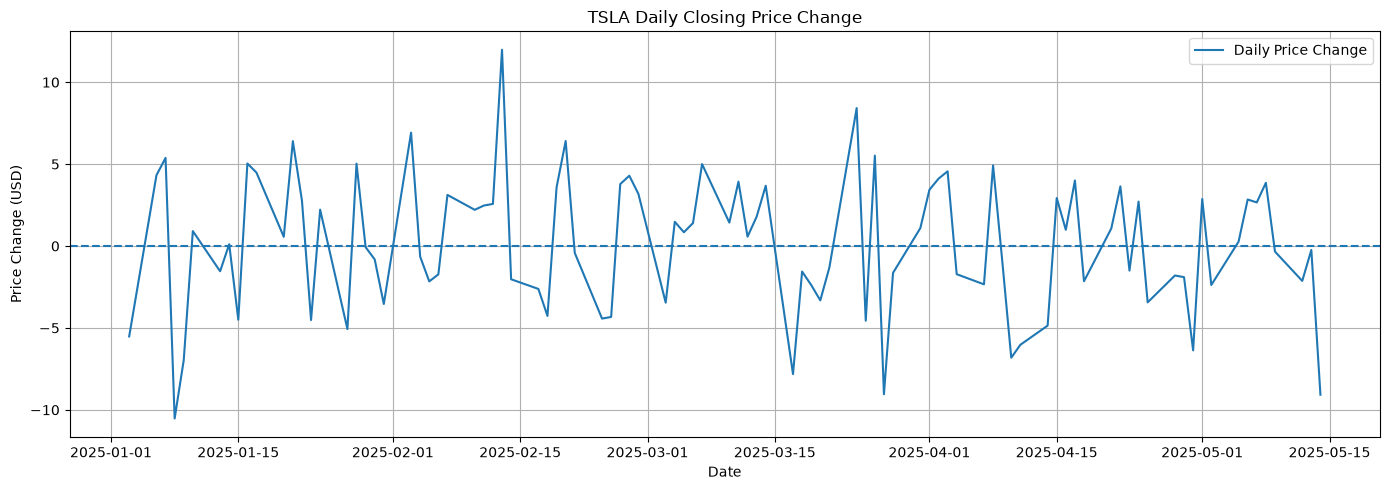

In [9]:
data["Daily_Change"] = data["Close"].diff()

plt.figure(figsize=(14, 5))

plt.plot(
    data.index,
    data["Daily_Change"],
    label="Daily Price Change"
)

plt.axhline(0, linestyle="--")

plt.title("TSLA Daily Closing Price Change")
plt.xlabel("Date")
plt.ylabel("Price Change (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
data.to_csv("TSLA_closing_price_analysis.csv")

print("TSLA closing price analysis saved successfully!")

TSLA closing price analysis saved successfully!



# TSLA Stock – Closing Price Trend Visualization

## Objectives
- Visualize historical TSLA closing prices.
- Identify short-term and long-term price trends.
- Analyse monthly average closing prices.
- Calculate 7-day and 30-day moving averages.
- Examine daily price changes.

## Methodology
1. Loaded the TSLA stock dataset.
2. Converted dates and closing prices into appropriate data types.
3. Sorted records chronologically.
4. Removed duplicate dates for time-series visualization.
5. Generated full-period and short-term line charts.
6. Calculated monthly average closing prices.
7. Added rolling averages to identify trends.
8. Visualized daily price changes.
9. Exported the processed dataset.

## Conclusion
Line visualizations were generated to examine the temporal movement of TSLA closing prices. Monthly averages and rolling averages were used to observe price trends across different time horizons. Daily price changes provided additional insight into short-term movements.

The visualizations support exploratory time-series analysis and can be used as a foundation for future stock price forecasting.
